# [1] 09 Alignment arrays: did the two-year clock exist before InSAR?

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. Seconds.
```

**What this notebook does.** The USGS Bay Area alignment arrays (archive v3.0)
give a 45-year record of surface slip at Tule Pond. Six arrays span the
section; HRKT (inside it) and HAPP (1.6 km north) were surveyed every ~2
months from 1979 to 2007 and annually after; HCAM and HPMD (~3 km south)
every ~2 months from 1990-92 to 2007; the others annually.

1. **Where the arrays are, and the arrays against the InSAR.** Positions
   (lat, lon) from the archive summary, checked against the mapped trace. The
   InSAR fault-parallel stack within 0.5 km along strike of each array
   (`stack_km`), tied to the array by the mean offset at the surveys inside
   the InSAR window (a vertical shift only); the array step across each InSAR
   onset (supplement figure: map + the six arrays since 2015).
2. **The HRKT event history, bimonthly era only.** An event is a survey
   interval whose step exceeds the inter-event rate by a fixed 6 mm (chosen
   by eye; the threshold sweep documents the choice), fitted with the same
   joint model as notebook 04; detections with a fitted step under 2 sigma
   are dropped. The output catalogue feeds 10 (event table, seasonality) and
   11 (repeat intervals and the forecast: the intervals live only there).
3. **Along strike.** The same detector on HAPP, HCAM and HPMD, and their
   step inside every HRKT event window: did the events reach them?
4. **Threshold sweep** (supplement): the detector at 3 sigma, 6 mm and 5 mm.

Ported from `Hayward_DISP-S1/analysis/run16_AA_insar_timeseries.py`,
`run18_aa_event_history.py` and `plotting/figS_hrkt_threshold_sweep.py`.

**Outputs** (`outputs/09_alignment_arrays/`): `hrkt_aa_events.csv` and
`aa_insar_stacks.csv` (read by 10 and 11), `aa_insar_steps.csv`,
`aa_alongstrike_neighbours.csv`, `hrkt_threshold_sweep.csv`, `09_aa_stats.txt`,
registry rows `09_*`.

**Figures**: the six-array supplement figure (`figS_tulepond_arrays_insar_*`),
the threshold sweep (supplement), and working figures of the HRKT and HAPP
records (`qc09_aa_history_*`; NOT the paper's Fig 3, which 11_forecast draws).

**What to check.** Every array within 150 m of the trace; HRKT's bimonthly era
ends late 2007; the quiet interval spans Loma Prieta; the neighbours stay
within noise inside the HRKT windows. Every number is registered in the last
cell (`09_*`).

In [1]:
# [2]
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import common_paths, params, paths_out, repo_dir

import h5py                                      # the velocity map (HDF5)
import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import pyproj                                    # lon/lat <-> UTM for the map
from scipy.spatial import cKDTree                 # nearest trace vertex (map: which side of the fault)
import pygmt                                     # the map panel
import xarray as xr                              # gridded data for pygmt
import matplotlib.pyplot as plt

## [3] Paths and parameters

In [2]:
# [4]
notebook = "09_alignment_arrays"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


stack_km = 0.5                 # half-width ALONG STRIKE of the InSAR stack around each array (Dani 2026-10-01: was 1 km of latitude)
site = "HRKT"                  # the array with the dense record
thr_mm = 6.0                   # detection threshold: fixed excess per survey interval, chosen by eye (see the sweep)
min_step_sigma = 2.0           # a detection is kept only if its fitted step is at least this many sigma (Dani 2026-10-02)
n_pass = 2                     # detector passes (pass 2 uses the fitted inter-event rate)
dense_window_days = 130        # the bimonthly era: survey intervals up to this; the detector runs only there (Dani 2026-10-02)
neighbour_codes = ["HAPP", "HCAM", "HPMD"]   # the other arrays surveyed every ~2 months: north (HAPP) and south (HCAM, HPMD) of the section
zoom_t0 = 2015.0               # start of the zoomed panels
loma_prieta = 1989.79
# the six arrays across the section, north -> south; their positions (lat AND lon) are read from the archive
# summary in [6] and checked against the mapped trace
array_codes = ["HAPP", "HGIL", "HRKT", "HHAN", "HUNI", "HPIN"]
max_trace_dist_m = 150.0       # every array must sit within this distance of the mapped trace
history_sites = ["HRKT", "HAPP"]   # the two arrays surveyed every ~2 months from 1979 to 2007 (working figure)
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")   # the fault-parallel velocity (map panel)
vel_lim = 4.0                  # map colour range, +/- mm/yr (as Fig 1A)

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_color, insar_color, det_color = "#08306B", "#D55E00", "#E69F00"   # array navy; InSAR vermillion; InSAR onsets orange (no two blues, no blue/green)

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, events_file, common_paths["aa_summary"], map_file,
           *[os.path.join(common_paths["aa_dir"], f"{code}.csv") for code in array_codes + ["HCAM", "HPMD"]])

Registry for 09_alignment_arrays: run 47f9de2d, git f466f9b+


## [5] Load: the InSAR fault-parallel time series, the InSAR catalogue, the arrays

In [3]:
# [6]
# the fault-parallel time series from 03: lat x decimal year, mm
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])    # latitude -> km from Point Pinole along the trace
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
fp_dates = fp_ts.columns.values.astype(float)

# the InSAR event catalogue from 04, Tule Pond only
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"]
insar_events = insar_events[["onset_yr", "onset_lo", "onset_hi", "amplitude_mm", "amp_lo", "amp_hi"]]
insar_events = insar_events.sort_values("onset_yr").reset_index(drop=True)
# 1 sigma from the 95% bootstrap bounds, to match the array errors: for a normal distribution the 95% interval
# spans mean +/- 1.96 sigma, so its full width is 2 x 1.96 = 3.92 sigma
insar_events["amp_err"] = (insar_events.amp_hi - insar_events.amp_lo) / 3.92
print("InSAR onsets:", [round(x, 3) for x in insar_events.onset_yr])

# the six arrays: year, cum_mm, std_mm each
arrays = {}
for code in array_codes:
    arrays[code] = utils.load_aa(common_paths["aa_dir"], code)
for code, array in arrays.items():
    print(f"  {code}: {len(array)} surveys {array.year.min():.2f} to {array.year.max():.2f}, "
          f"median spacing {np.median(np.diff(array.year)) * 365.25:.0f} d, "
          f"{array.cum_mm.iloc[-1] / (array.year.max() - array.year.min()):.2f} mm/yr over the record")

# the array positions: lat and lon from the archive summary. The along-strike km is taken from the array's own
# latitude (as the InSAR crossings are); the distance to the mapped trace is to its nearest 100 m vertex, so it
# is an upper bound (by up to ~50 m) on the distance to the line itself.
summary = utils.load_aa_summary(common_paths["aa_summary"]).set_index("site_code")
trace = pd.read_csv(common_paths["fault_profiles"])          # the mapped trace: ft_lon, ft_lat every 100 m
km_per_deg_lat = 111.19
km_per_deg_lon = 111.19 * np.cos(np.radians(trace.ft_lat.mean()))
position_rows = []
for code in array_codes:
    lat, lon = float(summary.loc[code, "lat_deg"]), float(summary.loc[code, "long_deg"])
    dist_km = np.hypot((trace.ft_lon.values - lon) * km_per_deg_lon, (trace.ft_lat.values - lat) * km_per_deg_lat)
    position_rows.append(dict(code=code, lat=lat, lon=lon, km=float(to_km([lat])[0]), dist_to_trace_m=1e3 * float(dist_km.min())))
array_pos = pd.DataFrame(position_rows).set_index("code")
print(array_pos.round({"lat": 4, "lon": 4, "km": 1, "dist_to_trace_m": 0}).to_string())
assert (array_pos.dist_to_trace_m <= max_trace_dist_m).all(), f"an array lies more than {max_trace_dist_m:g} m from the mapped trace"

InSAR onsets: [2017.099, 2019.186, 2021.107, 2023.08, 2024.984]
  HAPP: 174 surveys 1979.73 to 2024.68, median spacing 64 d, 6.00 mm/yr over the record
  HGIL: 45 surveys 1983.76 to 2024.93, median spacing 365 d, 5.99 mm/yr over the record
  HRKT: 177 surveys 1979.73 to 2024.72, median spacing 63 d, 5.73 mm/yr over the record
  HHAN: 30 surveys 1982.04 to 2024.72, median spacing 367 d, 6.22 mm/yr over the record
  HUNI: 34 surveys 1993.02 to 2024.82, median spacing 364 d, 6.65 mm/yr over the record
  HPIN: 36 surveys 1989.22 to 2024.82, median spacing 370 d, 7.21 mm/yr over the record
          lat       lon    km  dist_to_trace_m
code                                          
HAPP  37.5924 -122.0019  54.6             45.0
HGIL  37.5665 -121.9809  58.0             18.0
HRKT  37.5421 -121.9619  61.2             18.0
HHAN  37.5394 -121.9591  61.6             12.0
HUNI  37.5361 -121.9558  62.1             42.0
HPIN  37.5197 -121.9418  64.4            131.0


## [7] The InSAR stack at each array

The mean of the fault-parallel series of every crossing within `stack_km` along strike of
the array (crossings with fewer than half their dates are left out), tied to
the array by the mean offset at the surveys that fall inside the InSAR window.
A vertical shift only: nothing is fitted.

In [4]:
# [8]
def insar_stack(code, array):
    """(dates, slip_mm, n_crossings) of the InSAR stack at one array, tied to the array."""
    crossing_km = to_km(fp_ts.index.values.astype(float))      # fp_ts is indexed by latitude: along-strike km of each crossing
    array_km = float(array_pos.km[code])
    nearby = fp_ts[np.abs(crossing_km - array_km) <= stack_km]
    nearby = nearby[nearby.notna().sum(axis=1) > 0.5 * fp_ts.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        slip = np.nanmean(nearby.values, axis=0)
    ok = np.isfinite(slip)
    dates, slip = fp_dates[ok], slip[ok]
    # tie: the surveys inside the InSAR window, else the last survey against the first InSAR date
    in_window = array[(array.year >= dates.min()) & (array.year <= dates.max())]
    if len(in_window):
        offset = float(np.mean(in_window.cum_mm.values - np.interp(in_window.year.values, dates, slip)))
    else:
        offset = float(array.cum_mm.iloc[-1] - slip[0])
    return dates, slip + offset, len(nearby)


stacks = {}                                       # code -> (dates, slip_mm, n_crossings)
for code, array in arrays.items():
    stacks[code] = insar_stack(code, array)

# saved for notebooks 10 and 11; 11_forecast draws the paper's Fig 3 (HRKT record, onsets over the rain, intervals, forecast)
stack_rows = []
for code, (insar_dates, insar_slip, n_crossings) in stacks.items():
    stack_rows += [dict(code=code, date=date, slip_mm=slip, n_crossings=n_crossings) for date, slip in zip(insar_dates, insar_slip)]
pd.DataFrame(stack_rows).to_csv(os.path.join(out_dir, "aa_insar_stacks.csv"), index=False)

# the five event steps ON THE HRKT STACK, so the InSAR-era event size is compared with the array's dense-era steps at
# the same place (the 8.8 mm InSAR median of 04 is the peak band, km 58.2-59.8, not HRKT). Same joint model as 04:
# constant + rate + annual sin/cos + a Heaviside step at each onset, least squares.
hrkt_dates, hrkt_slip, hrkt_n = stacks["HRKT"]
G_hrkt = np.column_stack([np.ones_like(hrkt_dates), hrkt_dates - hrkt_dates.mean(), np.sin(2 * np.pi * hrkt_dates), np.cos(2 * np.pi * hrkt_dates)]
                         + [(hrkt_dates > onset).astype(float) for onset in insar_events.onset_yr])
hrkt_insar_steps = np.linalg.lstsq(G_hrkt, hrkt_slip, rcond=None)[0][4:]
assert len(hrkt_insar_steps) == len(insar_events) and np.all(np.isfinite(hrkt_insar_steps))
print(f"HRKT InSAR stack ({hrkt_n} crossings): event steps {np.round(hrkt_insar_steps, 1)} mm, mean {hrkt_insar_steps.mean():.1f}, median {np.median(hrkt_insar_steps):.1f}")

HRKT InSAR stack (10 crossings): event steps [6.7 6.9 6.1 5.4 6.5] mm, mean 6.3, median 6.5


## [9] The arrays against the InSAR at each site

For each InSAR onset, the array step between the surveys either side of it;
and, since 2015, the median step of survey intervals that contain an InSAR
onset against those that do not. At HGIL, inside the peak zone, the array
steps ~14 mm in event years and ~0 mm between: the array's own statement
of the sawtooth.

In [5]:
# [10]
stats_lines = ["09 ALIGNMENT ARRAYS",
               f"InSAR stack: crossings within +/-{stack_km:g} km of each array; tie: mean offset at surveys inside the InSAR window",
               "InSAR onsets: " + ", ".join(f"{x:.3f}" for x in insar_events.onset_yr), ""]
step_rows = []
for code, array in arrays.items():
    insar_dates, insar_slip, n_crossings = stacks[code]
    in_window = array[(array.year >= insar_dates.min()) & (array.year <= insar_dates.max())]
    stats_lines.append(f"{code} (km {array_pos.km[code]:.1f}, {array_pos.dist_to_trace_m[code]:.0f} m from the trace), stack {n_crossings} crossings; array {array.year.min():.2f}-{array.year.max():.2f}, "
                       f"{len(array)} surveys, {array.cum_mm.iloc[-1] / (array.year.max() - array.year.min()):.2f} mm/yr; "
                       f"InSAR {(insar_slip[-1] - insar_slip[0]) / (insar_dates[-1] - insar_dates[0]):.2f} mm/yr, {len(in_window)} surveys in window")
    # the array step across each InSAR onset: last survey before minus first survey after
    for onset in insar_events.onset_yr:
        before, after = array[array.year < onset], array[array.year > onset]
        if len(before) and len(after):
            survey_before, survey_after = before.iloc[-1], after.iloc[0]
            step_mm = survey_after.cum_mm - survey_before.cum_mm
            stats_lines.append(f"    {onset:.3f}: array step {step_mm:+5.1f} mm over {survey_before.year:.2f}-{survey_after.year:.2f} "
                               f"({(survey_after.year - survey_before.year) * 365.25:.0f} d)")
            step_rows.append(dict(code=code, onset=onset, step_mm=step_mm, from_yr=survey_before.year, to_yr=survey_after.year))
        else:
            stats_lines.append(f"    {onset:.3f}: not bracketed by surveys")
    # since zoom_t0: survey intervals that contain an InSAR onset against those that do not
    recent = array[array.year >= zoom_t0].reset_index(drop=True)
    event_steps, quiet_steps = [], []
    for i in range(1, len(recent)):
        step_mm = float(recent.cum_mm.iloc[i] - recent.cum_mm.iloc[i - 1])
        has_event = any(recent.year.iloc[i - 1] < onset < recent.year.iloc[i] for onset in insar_events.onset_yr)
        if has_event:
            event_steps.append(step_mm)
        else:
            quiet_steps.append(step_mm)
    if event_steps and quiet_steps:
        stats_lines.append(f"    intervals since {zoom_t0:.0f}: with an event {np.median(event_steps):+5.1f} mm (median, n = {len(event_steps)}) "
                           f"vs quiet {np.median(quiet_steps):+5.1f} mm (n = {len(quiet_steps)})")
        step_rows.append(dict(code=code, onset=np.nan, step_mm=np.median(event_steps), from_yr=np.nan, to_yr=np.nan, kind="event_median", n=len(event_steps)))
        step_rows.append(dict(code=code, onset=np.nan, step_mm=np.median(quiet_steps), from_yr=np.nan, to_yr=np.nan, kind="quiet_median", n=len(quiet_steps)))
    stats_lines.append("")
aa_steps = pd.DataFrame(step_rows)
aa_steps.to_csv(os.path.join(out_dir, "aa_insar_steps.csv"), index=False)
print("\n".join(stats_lines))

09 ALIGNMENT ARRAYS
InSAR stack: crossings within +/-0.5 km of each array; tie: mean offset at surveys inside the InSAR window
InSAR onsets: 2017.099, 2019.186, 2021.107, 2023.080, 2024.984

HAPP (km 54.6, 45 m from the trace), stack 9 crossings; array 1979.73-2024.68, 174 surveys, 6.00 mm/yr; InSAR 5.38 mm/yr, 8 surveys in window
    2017.099: array step  +7.4 mm over 2016.76-2017.79 (376 d)
    2019.186: array step  +7.4 mm over 2018.80-2019.82 (371 d)
    2021.107: array step +11.3 mm over 2019.82-2021.87 (749 d)
    2023.080: array step  +7.5 mm over 2022.79-2023.86 (391 d)
    2024.984: not bracketed by surveys
    intervals since 2015: with an event  +7.4 mm (median, n = 4) vs quiet  +6.6 mm (n = 4)

HGIL (km 58.0, 18 m from the trace), stack 11 crossings; array 1983.76-2024.93, 45 surveys, 5.99 mm/yr; InSAR 6.16 mm/yr, 8 surveys in window
    2017.099: array step +18.1 mm over 2016.76-2017.83 (388 d)
    2019.186: array step +11.4 mm over 2018.80-2019.82 (371 d)
    2021.107: ar

## [11] Supplement figure: where the six arrays are, and how the InSAR compares

A) map of the fault-parallel velocity (as Fig 1A, display-referenced to the mid-point of the two block
medians) with the mapped trace and the six arrays; B to G) each array since 2015 (navy, survey error
bars) with the InSAR stack tied to it (orange) and the five InSAR onsets (dashed). The map is drawn
with pygmt and placed in the matplotlib figure as an image (one 600 dpi PNG).

psconvert [WARNING]: The -N+g or -N+p options do not support the -!


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/figS_tulepond_arrays_insar_ap30-150m_coh0.7_mp5_sw200m_stack0.5km.png


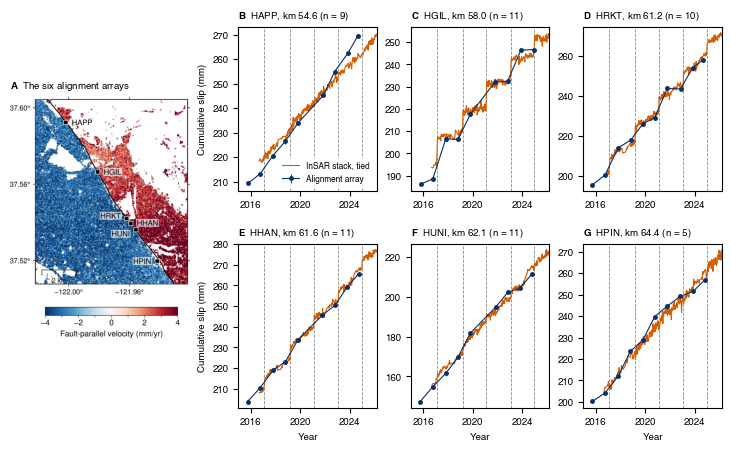

In [6]:
# [12]
# --- A) the map: the velocity grid resampled onto a lon/lat grid over the arrays (nearest node), north up
with h5py.File(map_file, "r") as hf:
    fp_map = hf["fp_velocity"][:].astype(float)
    attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in hf.attrs.items()}
fp_map[fp_map == 0] = np.nan
map_region = [array_pos.lon.min() - 0.02, array_pos.lon.max() + 0.02, array_pos.lat.min() - 0.012, array_pos.lat.max() + 0.012]
lon_axis = np.arange(map_region[0], map_region[1], 0.0003)
lat_axis = np.arange(map_region[2], map_region[3], 0.0003)
lon_grid, lat_grid = np.meshgrid(lon_axis, lat_axis)
easting, northing = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True).transform(lon_grid, lat_grid)
col = np.round((easting - float(attrs["X_FIRST"])) / float(attrs["X_STEP"])).astype(int)
row = np.round((northing - float(attrs["Y_FIRST"])) / float(attrs["Y_STEP"])).astype(int)
on_grid = (col >= 0) & (col < fp_map.shape[1]) & (row >= 0) & (row < fp_map.shape[0])
fp_lonlat = np.full(lon_grid.shape, np.nan)
fp_lonlat[on_grid] = fp_map[row[on_grid], col[on_grid]]
# display reference: the mid-point of the median velocity west and east of the trace inside the map
# side of the fault: the cross product of the local trace direction (turned to run north to south) with the
# vector from the nearest trace vertex to the node; positive = to the left of a south-going trace = east
trace_x, trace_y = trace.ft_lon.values * km_per_deg_lon, trace.ft_lat.values * km_per_deg_lat
node_x, node_y = lon_grid.ravel() * km_per_deg_lon, lat_grid.ravel() * km_per_deg_lat
nearest = cKDTree(np.c_[trace_x, trace_y]).query(np.c_[node_x, node_y])[1]
ahead, behind = np.clip(nearest + 1, 0, len(trace_x) - 1), np.clip(nearest - 1, 0, len(trace_x) - 1)
dir_x, dir_y = trace_x[ahead] - trace_x[behind], trace_y[ahead] - trace_y[behind]
if trace.ft_lat.values[0] < trace.ft_lat.values[-1]:          # the file runs south to north: turn the direction south-going
    dir_x, dir_y = -dir_x, -dir_y
east_of_trace = (dir_x * (node_y - trace_y[nearest]) - dir_y * (node_x - trace_x[nearest]) > 0).reshape(lon_grid.shape)
assert 0.2 < east_of_trace.mean() < 0.8, f"east/west split looks wrong: {east_of_trace.mean():.2f} of the map east of the trace"
fp_lonlat = fp_lonlat - 0.5 * (np.nanmedian(fp_lonlat[~east_of_trace]) + np.nanmedian(fp_lonlat[east_of_trace]))
grid_ll = xr.DataArray(fp_lonlat, coords={"lat": lat_axis, "lon": lon_axis}, dims=("lat", "lon"))
cpt_vel = utils.write_cpt(os.path.join(out_dir, "vel_RdBu_r.cpt"), "RdBu_r", -vel_lim, vel_lim)

map_png = os.path.join(out_dir, "qc09_arrays_map_panel.png")
gmt_map = pygmt.Figure()
with pygmt.config(FONT="7p,Helvetica", FONT_ANNOT_PRIMARY="6p,Helvetica", MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p",
                  MAP_TICK_LENGTH_PRIMARY="2p", FORMAT_GEO_MAP="ddd.xx"):
    gmt_map.basemap(region=map_region, projection="M4.6c", frame=["WSne", "xa0.04", "ya0.04"])
    gmt_map.grdimage(grid=grid_ll, cmap=cpt_vel, nan_transparent=True)
    gmt_map.plot(x=trace.ft_lon.values, y=trace.ft_lat.values, pen="0.7p,black")
    gmt_map.plot(x=array_pos.lon.values, y=array_pos.lat.values, style="s0.18c", fill="black", pen="0.4p,white")
    # labels on alternating sides: HRKT, HHAN and HUNI lie within 1 km of each other along the trace
    label_side = {"HAPP": ("LM", "0.18c/0c"), "HGIL": ("LM", "0.18c/0c"), "HRKT": ("RM", "-0.18c/0.08c"),
                  "HHAN": ("LM", "0.18c/0.02c"), "HUNI": ("RM", "-0.18c/-0.12c"), "HPIN": ("RM", "-0.18c/0c")}
    for code, p in array_pos.iterrows():
        justify, offset = label_side[code]
        utils.text_backed(gmt_map, x=p.lon, y=p.lat, text=code, justify=justify, offset=offset, font="6.5p,Helvetica")
    gmt_map.basemap(map_scale="jBL+w2k+o0.2c/0.25c")
with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):        # -> ~6.5 pt at this bar thickness (as Fig 1)
    gmt_map.colorbar(cmap=cpt_vel, position="JBC+w4.0c/0.25c+h+o0c/0.7c", frame="xa2f1+lFault-parallel velocity (mm/yr)")
gmt_map.savefig(map_png, dpi=600, crop="+gwhite")

# --- B to G) the arrays since 2015 against the InSAR, two rows of three, beside the map
utils.mpl_paper_style(base=7)
fig = plt.figure(figsize=(7.2, 4.4), constrained_layout=True)          # 18.3 cm wide
grid_spec = fig.add_gridspec(2, 4, width_ratios=[1.3, 1, 1, 1])
ax_map = fig.add_subplot(grid_spec[:, 0])
ax_map.imshow(plt.imread(map_png))
ax_map.axis("off")
utils.panel_title(ax_map, "A", "The six alignment arrays")
for i, (code, array) in enumerate(arrays.items()):
    insar_dates, insar_slip, n_crossings = stacks[code]
    ax = fig.add_subplot(grid_spec[i // 3, 1 + i % 3])
    recent = array.year >= zoom_t0
    ax.errorbar(array.year[recent], array.cum_mm[recent], yerr=array.std_mm[recent], fmt="o", ms=2.5, color=aa_color, ecolor=aa_color,
                elinewidth=0.6, lw=0.8, ls="-", label="Alignment array")
    ax.plot(insar_dates, insar_slip, "-", lw=0.8, color=insar_color, label="InSAR stack, tied")
    for onset in insar_events.onset_yr:
        ax.axvline(onset, color="0.55", lw=0.6, ls="--", zorder=0)
    ax.set_xlim(zoom_t0, 2026.2)
    ax.set_xticks([2016, 2020, 2024])
    y_lo = min(np.nanmin(insar_slip), array.cum_mm[recent].min())
    y_hi = max(np.nanmax(insar_slip), array.cum_mm[recent].max())
    ax.set_ylim(y_lo - 3, y_hi + 3)
    if i % 3 == 0:
        ax.set_ylabel("Cumulative slip (mm)")
    if i >= 3:
        ax.set_xlabel("Year")
    if i == 0:
        ax.legend(fontsize=6, loc="lower right")
    utils.panel_title(ax, "BCDEFG"[i], f"{code}, km {array_pos.km[code]:.1f} (n = {n_crossings})", size=7)
f_arrays = os.path.join(fig_dir, f"figS_tulepond_arrays_insar_{params}_stack{stack_km:g}km.png")
fig.savefig(f_arrays, dpi=600)
fig.savefig(f_arrays.replace(".png", ".pdf"))
print("Saved figure to:", f_arrays)
plt.show()

## [13] The HRKT event history (the bimonthly era only)

HRKT was surveyed every ~2 months until the end of 2007, then annually. The detector and the joint model
run on the bimonthly era only (Dani 2026-10-02): the annual cycle in the model cannot be resolved from
annual surveys, and a one-year window cannot place an event in its season. The era ends at the last
survey that closes an interval of `dense_window_days` or less.

Detection on survey intervals: `excess = (cum_i - cum_{i-1}) - rate * (t_i - t_{i-1})` beats `thr_mm`
(a fixed threshold chosen by eye against the visually clear steps; the sweep below shows the choice). The
flagged intervals are fitted with the joint model (constant + rate + annual sin/cos + one step per event);
where in its window a step is placed does not change the fit, since no survey falls inside the window.
Any event whose fitted step is under `min_step_sigma` times its 1-sigma error is dropped (the weakest
first) and the model refitted. Pass 2 repeats the detection with the fitted inter-event rate.

The quiet interval is the longest gap between detections; it spans Loma Prieta.

In [7]:
# [14]
def design_matrix(dates, onsets):
    """Columns: constant, rate, annual sin and cos, then one step per onset."""
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    columns += [(dates > onset).astype(float) for onset in onsets]
    return np.column_stack(columns)


def bimonthly_era(array):
    """The array up to the last survey that closes an interval of dense_window_days or less."""
    gap_days = np.diff(array.year.values) * 365.25
    last = int(np.max(np.where(gap_days <= dense_window_days)[0])) + 1
    return array.iloc[:last + 1].reset_index(drop=True)


def detect_intervals(survey_yr, cum_slip, rate_mm_yr, threshold_mm):
    """Survey intervals whose excess step beats the threshold, as (i_start, i_end)
    index pairs; consecutive flagged intervals are merged into one. Also returns
    the excess of every interval."""
    excess = np.diff(cum_slip) - rate_mm_yr * np.diff(survey_yr)
    events = []
    for i in np.where(excess > threshold_mm)[0]:
        if events and i == events[-1][1]:            # continues the previous flagged interval
            events[-1][1] = i + 1
        else:
            events.append([i, i + 1])
    return [(i_start, i_end) for i_start, i_end in events], excess


def fit_steps(survey_yr, cum_slip, events):
    """The joint model with one step per event: (coef, design_G, step 1-sigma errors)."""
    onsets = [0.5 * (survey_yr[i_start] + survey_yr[i_end]) for i_start, i_end in events]   # any time inside the window gives the same fit
    design_G = design_matrix(survey_yr, onsets)
    coef, *_ = np.linalg.lstsq(design_G, cum_slip, rcond=None)
    residual = cum_slip - np.dot(design_G, coef)                       # np.dot(G, coef) = the model at every survey
    variance = float(np.sum(residual ** 2) / (len(survey_yr) - design_G.shape[1]))
    step_err = np.sqrt(variance * np.diag(np.linalg.inv(np.dot(design_G.T, design_G))))[4:]
    return coef, design_G, step_err


def run_detector(survey_yr, cum_slip, threshold_mm):
    """Two passes of detection + joint fit, dropping steps under min_step_sigma x their error.
    Returns (catalogue, excess, inter_event_rate, coef, design_G, n_dropped)."""
    inter_event_rate = float(np.polyfit(survey_yr, cum_slip, 1)[0])          # pass 1: the global rate
    for _ in range(n_pass):
        events, excess = detect_intervals(survey_yr, cum_slip, inter_event_rate, threshold_mm)
        n_dropped = 0
        while True:
            coef, design_G, step_err = fit_steps(survey_yr, cum_slip, events)
            if len(events) == 0:
                break
            ratio = coef[4:] / step_err
            if ratio.min() >= min_step_sigma:
                break
            i_start, i_end = events.pop(int(np.argmin(ratio)))               # the weakest event goes first
            n_dropped += 1
            print(f"      dropped {survey_yr[i_start]:.2f}-{survey_yr[i_end]:.2f}: fitted step {ratio.min():.1f} sigma (< {min_step_sigma:g})")
        inter_event_rate = float(coef[1])                                     # pass 2 uses the fitted rate
    catalogue = pd.DataFrame([dict(onset_yr=0.5 * (survey_yr[i_start] + survey_yr[i_end]), onset_lo=survey_yr[i_start], onset_hi=survey_yr[i_end],
                                   window_days=(survey_yr[i_end] - survey_yr[i_start]) * 365.25,
                                   amplitude_mm=float(amplitude), amp_err=float(err))
                              for (i_start, i_end), amplitude, err in zip(events, coef[4:], step_err)],
                             columns=["onset_yr", "onset_lo", "onset_hi", "window_days", "amplitude_mm", "amp_err"])   # columns kept when empty
    return catalogue, excess, inter_event_rate, coef, design_G, n_dropped


hrkt = bimonthly_era(arrays[site])
survey_yr = hrkt.year.values
cum_slip = hrkt.cum_mm.values
dense_era_end = float(survey_yr[-1])
hrkt_events, excess, inter_event_rate, coef, design_G, n_dropped = run_detector(survey_yr, cum_slip, thr_mm)
excess_sigma = utils.robust_sigma(excess)
annual_mm = float(np.hypot(coef[2], coef[3]))
rms_mm = float(np.sqrt(np.mean((cum_slip - np.dot(design_G, coef)) ** 2)))
assert len(hrkt_events) > 0, f"no {site} events at {thr_mm:g} mm"
assert hrkt_events.window_days.max() <= dense_window_days, "an event window longer than the bimonthly cadence"
# the event catalogue for 10 (the event table, the seasonality) and 11 (the forecast). onset_yr is the window
# midpoint, a label only: every use of the onset draws it uniformly within [onset_lo, onset_hi]
hrkt_events.round(4).to_csv(os.path.join(out_dir, f"{site.lower()}_aa_events.csv"), index=False)

print(f"{site} bimonthly era: {len(survey_yr)} surveys {survey_yr.min():.2f}-{dense_era_end:.2f}, "
      f"median spacing {np.median(np.diff(survey_yr)) * 365.25:.0f} d (annual surveys after {dense_era_end:.2f} are not used)")
print(f"threshold {thr_mm:g} mm = {thr_mm / excess_sigma:.1f} robust sigma (sigma {excess_sigma:.2f} mm); "
      f"joint model: inter-event rate {inter_event_rate:.2f} mm/yr, annual {annual_mm:.2f} mm, rms {rms_mm:.2f} mm; "
      f"{n_dropped} detection(s) dropped under {min_step_sigma:g} sigma")
print(f"{len(hrkt_events)} events, steps {hrkt_events.amplitude_mm.min():.1f} to {hrkt_events.amplitude_mm.max():.1f} mm "
      f"(median {hrkt_events.amplitude_mm.median():.1f})")
# the event table: the onset is known only to the survey window (window_lo = last survey before the step,
# window_hi = first survey after it); the step is the joint-model amplitude with its 1-sigma formal error
event_table = hrkt_events[["onset_lo", "onset_hi", "window_days", "amplitude_mm", "amp_err"]].rename(
    columns={"onset_lo": "window_lo (yr)", "onset_hi": "window_hi (yr)", "window_days": "window (d)",
             "amplitude_mm": "step (mm)", "amp_err": "1-sigma (mm)"})
print(event_table.round({"window_lo (yr)": 2, "window_hi (yr)": 2, "window (d)": 0, "step (mm)": 1, "1-sigma (mm)": 1}).to_string(index=False))

# the quiet interval: the longest gap between detections; the surveys inside it and their largest step
gaps_yr = hrkt_events.onset_lo.values[1:] - hrkt_events.onset_hi.values[:-1]
i_gap = int(np.argmax(gaps_yr))
quiet_start, quiet_end = float(hrkt_events.onset_hi.values[i_gap]), float(hrkt_events.onset_lo.values[i_gap + 1])
in_quiet = (survey_yr >= quiet_start) & (survey_yr <= quiet_end)
n_quiet = int(((survey_yr > quiet_start) & (survey_yr < quiet_end)).sum())
max_step_quiet = float(np.max(np.diff(cum_slip[in_quiet])))
print(f"quiet interval {quiet_start:.2f} to {quiet_end:.2f} ({quiet_end - quiet_start:.1f} yr): {n_quiet} surveys, "
      f"largest step {max_step_quiet:.1f} mm; Loma Prieta {loma_prieta}")
assert quiet_start < loma_prieta < quiet_end, "the longest quiet interval no longer spans Loma Prieta: check the catalogue"

HRKT bimonthly era: 159 surveys 1979.73-2007.44, median spacing 63 d (annual surveys after 2007.44 are not used)
threshold 6 mm = 2.5 robust sigma (sigma 2.43 mm); joint model: inter-event rate 2.95 mm/yr, annual 1.90 mm, rms 2.11 mm; 0 detection(s) dropped under 2 sigma
9 events, steps 2.2 to 12.3 mm (median 8.2)
 window_lo (yr)  window_hi (yr)  window (d)  step (mm)  1-sigma (mm)
        1983.05         1983.39       124.0        9.2           0.9
        1985.95         1986.18        85.0        6.5           0.9
        1988.29         1988.41        43.0        2.2           1.0
        1993.18         1993.35        63.0        6.8           1.0
        1997.32         1997.47        56.0       10.0           0.9
        2000.06         2000.23        63.0       12.3           0.9
        2002.86         2003.03        63.0        8.2           1.0
        2004.99         2005.18        69.0        9.0           1.3
        2005.87         2006.06        70.0        4.6         

## [15] Along strike: did the events reach the neighbouring dense arrays?

Three other arrays were surveyed every ~2 months: HAPP (km 54.6, 1.6 km north of the section) and HCAM and
HPMD (km 65.3 and 65.7, ~3 km south of it). For each, over its own bimonthly era: its own detections at the
same threshold, and its excess step (slip minus its rate x window) over the window of every HRKT event it
covers. An event that reached the array would step it inside the HRKT window.

In [8]:
# [16]
neighbour_rows = []
neighbour_runs = {}
for code in neighbour_codes:
    array = bimonthly_era(utils.load_aa(common_paths["aa_dir"], code))
    years, cum = array.year.values, array.cum_mm.values
    own_events, own_excess, own_rate, _, _, _ = run_detector(years, cum, thr_mm)
    own_sigma = utils.robust_sigma(own_excess)
    neighbour_runs[code] = (array, own_events, own_excess, own_sigma)
    print(f"{code}: bimonthly era {years.min():.2f}-{years.max():.2f}, {len(years)} surveys, sigma {own_sigma:.2f} mm "
          f"({thr_mm:g} mm = {thr_mm / own_sigma:.1f} sigma), {len(own_events)} own events"
          + (": " + ", ".join(f"{e.onset_lo:.2f}-{e.onset_hi:.2f} ({e.amplitude_mm:.1f} mm)" for e in own_events.itertuples()) if len(own_events) else ""))
    for event in hrkt_events.itertuples():
        if event.onset_lo < years.min() or event.onset_hi > years.max():
            continue                                                       # this HRKT window is outside the array's bimonthly era
        step = np.interp(event.onset_hi, years, cum) - np.interp(event.onset_lo, years, cum)
        excess_here = step - own_rate * (event.onset_hi - event.onset_lo)
        neighbour_rows.append(dict(array=code, hrkt_window_lo=event.onset_lo, hrkt_window_hi=event.onset_hi, hrkt_step_mm=event.amplitude_mm,
                                   excess_mm=excess_here, excess_sigma=excess_here / own_sigma))
        print(f"  HRKT {event.onset_lo:.2f}-{event.onset_hi:.2f} ({event.amplitude_mm:4.1f} mm): {code} excess {excess_here:+5.1f} mm "
              f"({excess_here / own_sigma:+.1f} sigma)")
neighbours = pd.DataFrame(neighbour_rows)
neighbours.round(3).to_csv(os.path.join(out_dir, "aa_alongstrike_neighbours.csv"), index=False)
print(f"largest excess at a neighbour inside an HRKT window: {neighbours.excess_sigma.max():+.1f} sigma "
      f"({len(neighbours)} array-windows)")

HAPP: bimonthly era 1979.73-2007.84, 157 surveys, sigma 1.92 mm (6 mm = 3.1 sigma), 0 own events
  HRKT 1983.05-1983.39 ( 9.2 mm): HAPP excess  -3.8 mm (-2.0 sigma)
  HRKT 1985.95-1986.18 ( 6.5 mm): HAPP excess  +0.7 mm (+0.3 sigma)
  HRKT 1988.29-1988.41 ( 2.2 mm): HAPP excess  +0.5 mm (+0.3 sigma)
  HRKT 1993.18-1993.35 ( 6.8 mm): HAPP excess  -2.0 mm (-1.0 sigma)
  HRKT 1997.32-1997.47 (10.0 mm): HAPP excess  +1.6 mm (+0.9 sigma)
  HRKT 2000.06-2000.23 (12.3 mm): HAPP excess  -0.7 mm (-0.4 sigma)
  HRKT 2002.86-2003.03 ( 8.2 mm): HAPP excess  +0.7 mm (+0.3 sigma)
  HRKT 2004.99-2005.17 ( 9.0 mm): HAPP excess  -0.3 mm (-0.2 sigma)
  HRKT 2005.87-2006.06 ( 4.6 mm): HAPP excess  -0.8 mm (-0.4 sigma)
HCAM: bimonthly era 1990.12-2007.84, 105 surveys, sigma 1.28 mm (6 mm = 4.7 sigma), 1 own events: 1995.96-1996.13 (9.3 mm)
  HRKT 1993.18-1993.35 ( 6.8 mm): HCAM excess  -1.9 mm (-1.5 sigma)
  HRKT 1997.32-1997.47 (10.0 mm): HCAM excess  -0.8 mm (-0.7 sigma)
  HRKT 2000.06-2000.23 (12.3 mm)

## [17] Working figures: the 45-year record at the two longest dense arrays (not the paper's Fig 3)

HRKT (km 61.2, inside the section) and HAPP (km 54.6, north of it). One figure per array: the whole
record with its own detections shaded (bimonthly era) and an inset since 2015 against the InSAR; the
detection statistic over the bimonthly era. HRKT's windows are outlined on HAPP's panels.

Saved the working HRKT history figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/qc09_aa_history_HRKT_thr6mm_nev9.png


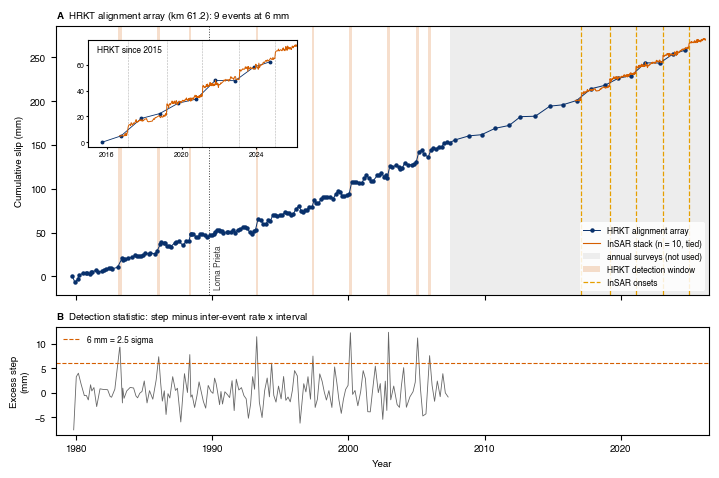

Saved the working HAPP history figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/qc09_aa_history_HAPP_thr6mm_nev0.png


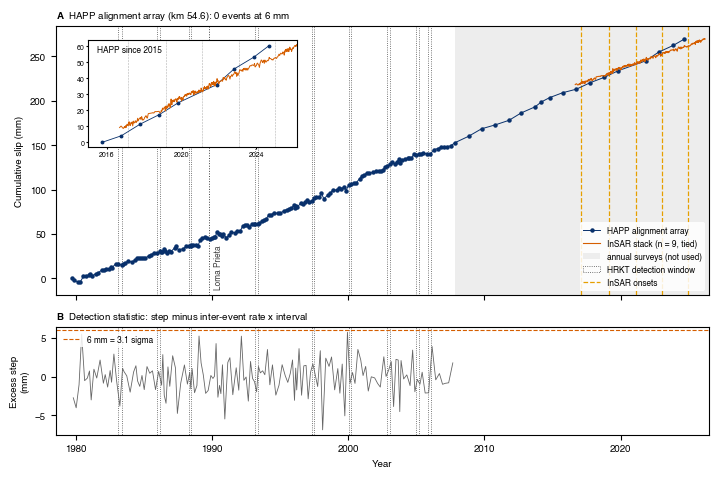

In [9]:
# [18]
def draw_history(code, catalogue, excess_code, sigma_code, era_end, reference_windows=None):
    """One working figure for one array (see the cell above)."""
    array = arrays[code]
    era = array[array.year <= era_end + 1e-9]
    insar_dates, insar_slip, n_crossings = stacks[code]
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.8), sharex=True, height_ratios=[1.5, 0.6])
    # A) the record, its detections shaded, the InSAR onsets dashed
    ax = axes[0]
    ax.plot(array.year, array.cum_mm, "o", ms=2.2, color=aa_color, lw=0.7, ls="-", zorder=3, label=f"{code} alignment array")
    ax.plot(insar_dates, insar_slip, "-", lw=0.8, color=insar_color, zorder=5, label=f"InSAR stack (n = {n_crossings}, tied)")
    ax.axvspan(era_end, 2026.5, color="0.93", lw=0, zorder=0, label="annual surveys (not used)")
    for event in catalogue.itertuples():
        ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.20, lw=0, zorder=1,
                   label=f"{code} detection window" if event.Index == 0 else None)
    if reference_windows is not None:
        for j, event in enumerate(reference_windows.itertuples()):
            ax.axvspan(event.onset_lo, event.onset_hi, facecolor="none", edgecolor="0.3", lw=0.6, ls=":", zorder=2,
                       label="HRKT detection window" if j == 0 else None)
    for i, onset in enumerate(insar_events.onset_yr):
        ax.axvline(onset, color=det_color, lw=0.9, ls="--", zorder=2, label="InSAR onsets" if i == 0 else None)
    ax.axvline(loma_prieta, color="0.25", lw=0.7, ls=":", zorder=2)
    ax.text(loma_prieta + 0.35, 0.02, "Loma Prieta", transform=ax.get_xaxis_transform(), rotation=90, fontsize=6, color="0.25", va="bottom")
    ax.set_ylabel("Cumulative slip (mm)")
    ax.legend(fontsize=6, loc="lower right")
    utils.panel_title(ax, "A", f"{code} alignment array (km {array_pos.km[code]:.1f}): {len(catalogue)} events at {thr_mm:g} mm")
    # the inset: this array since 2015 against its InSAR stack, zeroed at the first survey
    recent = array[array.year >= zoom_t0]
    zero = float(recent.cum_mm.iloc[0])
    inset = ax.inset_axes([0.05, 0.55, 0.32, 0.40])
    inset.plot(recent.year, recent.cum_mm - zero, "o", ms=1.8, color=aa_color, lw=0.6, ls="-")
    inset.plot(insar_dates, insar_slip - zero, "-", lw=0.7, color=insar_color)
    for onset in insar_events.onset_yr:
        inset.axvline(onset, color="0.7", lw=0.4, ls="--", zorder=0)
    inset.set_xlim(zoom_t0, 2026.2)
    inset.set_xticks([2016, 2020, 2024])
    inset.tick_params(labelsize=5, length=1.5, pad=1.5)
    inset.text(0.04, 0.95, f"{code} since {zoom_t0:.0f}", transform=inset.transAxes, fontsize=6, va="top")
    # B) the detection statistic over the bimonthly era
    ax = axes[1]
    ax.plot(0.5 * (era.year.values[1:] + era.year.values[:-1]), excess_code, "-", lw=0.6, color="0.4")
    ax.axhline(thr_mm, color=insar_color, lw=0.8, ls="--", label=f"{thr_mm:g} mm = {thr_mm / sigma_code:.1f} sigma")
    if reference_windows is not None:
        for event in reference_windows.itertuples():
            ax.axvspan(event.onset_lo, event.onset_hi, facecolor="none", edgecolor="0.3", lw=0.6, ls=":")
    ax.set_ylabel("Excess step\n(mm)")
    ax.legend(fontsize=6, loc="upper left")
    utils.panel_title(ax, "B", "Detection statistic: step minus inter-event rate x interval")
    axes[-1].set_xlabel("Year")
    axes[-1].set_xlim(1978.5, 2026.5)
    fig.tight_layout()
    f_history = os.path.join(fig_dir, f"qc09_aa_history_{code}_thr{thr_mm:g}mm_nev{len(catalogue)}.png")
    fig.savefig(f_history, dpi=300)
    print(f"Saved the working {code} history figure to: {f_history}")
    plt.show()


happ_era, happ_events, happ_excess, happ_sigma = bimonthly_era(arrays["HAPP"]), *neighbour_runs["HAPP"][1:]
draw_history("HRKT", hrkt_events, excess, excess_sigma, dense_era_end)
draw_history("HAPP", happ_events, happ_excess, happ_sigma, float(happ_era.year.max()), reference_windows=hrkt_events)

## [19] Threshold sweep (supplement)

The same detector (bimonthly era, the 2-sigma step rule) at the relative 3 sigma cut, at 6 mm and at 5 mm.
Left: the detection statistic with each threshold and the detected windows. Right: the fitted step of each
detected event with its 1-sigma error.

threshold 3 sigma = 7.5 mm:
      dropped 1988.29-1988.41: fitted step -1.2 sigma (< 2)
threshold 6 mm:
threshold 5 mm:
      dropped 2003.97-2004.14: fitted step 1.1 sigma (< 2)
       threshold  thr_mm  n_events  n_dropped  rate
3 sigma = 7.5 mm    7.54         5          1  4.24
            6 mm    6.00         9          0  2.95
            5 mm    5.00        12          1  2.44


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/figS_hrkt_threshold_sweep_3sig-6mm-5mm.png


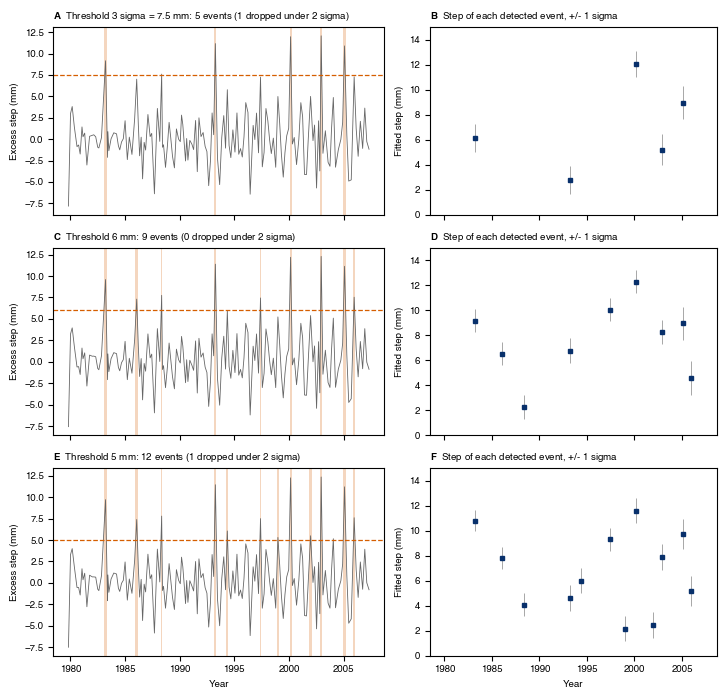

In [10]:
# [20]
# the robust sigma of the excess at the global rate sets the "3 sigma" case
global_rate = float(np.polyfit(survey_yr, cum_slip, 1)[0])
_, excess_global = detect_intervals(survey_yr, cum_slip, global_rate, 1e9)
sigma_global = utils.robust_sigma(excess_global)
cases = [(f"3 sigma = {3 * sigma_global:.1f} mm", 3 * sigma_global), ("6 mm", 6.0), ("5 mm", 5.0)]

fig, axes = plt.subplots(len(cases), 2, figsize=(7.2, 7.0), width_ratios=[1.15, 1.0], sharex=True)
sweep_rows = []
for i_case, (label, threshold_mm) in enumerate(cases):
    print(f"threshold {label}:")
    sweep_events, sweep_excess, sweep_rate, sweep_coef, sweep_G, sweep_dropped = run_detector(survey_yr, cum_slip, threshold_mm)
    sweep_rows.append(dict(threshold=label, thr_mm=threshold_mm, n_events=len(sweep_events), n_dropped=sweep_dropped, rate=sweep_rate))
    # left: the detection statistic with this threshold
    ax = axes[i_case, 0]
    ax.plot(0.5 * (survey_yr[1:] + survey_yr[:-1]), sweep_excess, "-", lw=0.6, color="0.4")
    ax.axhline(threshold_mm, color=insar_color, lw=0.9, ls="--")
    for event in sweep_events.itertuples():
        ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.25, lw=0)
    ax.set_ylabel("Excess step (mm)")
    utils.panel_title(ax, "ACE"[i_case], f"Threshold {label}: {len(sweep_events)} events ({sweep_dropped} dropped under {min_step_sigma:g} sigma)")
    # right: the fitted steps
    ax = axes[i_case, 1]
    ax.errorbar(0.5 * (sweep_events.onset_lo + sweep_events.onset_hi), sweep_events.amplitude_mm, yerr=sweep_events.amp_err,
                fmt="s", ms=3.2, color=aa_color, ecolor="0.6", elinewidth=0.6, ls="none")
    ax.set_ylim(0, 15)
    ax.set_ylabel("Fitted step (mm)")
    utils.panel_title(ax, "BDF"[i_case], "Step of each detected event, +/- 1 sigma")
    if i_case == len(cases) - 1:
        axes[i_case, 0].set_xlabel("Year")
        ax.set_xlabel("Year")
fig.tight_layout()
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(os.path.join(out_dir, "hrkt_threshold_sweep.csv"), index=False)
print(sweep.round(2).to_string(index=False))
f_sweep = os.path.join(fig_dir, "figS_hrkt_threshold_sweep_3sig-6mm-5mm.png")
fig.savefig(f_sweep, dpi=300)
fig.savefig(f_sweep.replace(".png", ".pdf"))
print("Saved figure to:", f_sweep)
plt.show()

## [21] REGISTER

In [11]:
# [22]
stats_lines += [f"{site} EVENT HISTORY (bimonthly era {survey_yr.min():.2f}-{dense_era_end:.2f}): {len(survey_yr)} surveys, "
                f"median spacing {np.median(np.diff(survey_yr)) * 365.25:.0f} d",
                f"detection: fixed {thr_mm:g} mm excess per interval (= {thr_mm / excess_sigma:.1f} robust sigma, sigma {excess_sigma:.2f} mm); "
                f"steps under {min_step_sigma:g} sigma dropped ({n_dropped}); joint model rate {inter_event_rate:.2f} mm/yr, "
                f"annual {annual_mm:.2f} mm, rms {rms_mm:.2f} mm",
                f"{len(hrkt_events)} events, steps {hrkt_events.amplitude_mm.min():.1f}-{hrkt_events.amplitude_mm.max():.1f} mm "
                f"(median {hrkt_events.amplitude_mm.median():.1f})"]
stats_lines += [f"  window {event.onset_lo:.2f}-{event.onset_hi:.2f} ({event.window_days:3.0f} d)  step {event.amplitude_mm:5.1f} +/- {event.amp_err:.1f} mm"
                for event in hrkt_events.itertuples()]
stats_lines += [f"quiet interval {quiet_start:.2f}-{quiet_end:.2f} ({quiet_end - quiet_start:.1f} yr), {n_quiet} surveys, "
                f"largest step {max_step_quiet:.1f} mm, spans Loma Prieta {loma_prieta}",
                f"InSAR-era steps on the HRKT stack: mean {hrkt_insar_steps.mean():.1f}, median {np.median(hrkt_insar_steps):.1f} mm",
                "", "along strike (neighbour excess inside HRKT windows):", neighbours.round(2).to_string(index=False),
                "", "threshold sweep:", sweep.round(2).to_string(index=False)]
sidecar = REG.sidecar("09_aa", stats_lines)

REG.register("09_hrkt_n_surveys", len(survey_yr), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_first_yr", survey_yr.min(), "decyear", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_dense_era_end_yr", dense_era_end, "decyear", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_median_spacing_d", np.median(np.diff(survey_yr)) * 365.25, "d", 0, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_sigma_mm", excess_sigma, "mm", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_threshold_sigma", thr_mm / excess_sigma, "1", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_rate_mm_yr", inter_event_rate, "mm/yr", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_annual_mm", annual_mm, "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_n_events", len(hrkt_events), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_n_dropped_2sigma", n_dropped, "count", 0, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_amp_min_mm", hrkt_events.amplitude_mm.min(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_amp_max_mm", hrkt_events.amplitude_mm.max(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_amp_median_mm", hrkt_events.amplitude_mm.median(), "mm", 1, where="P9", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_amp_mean_mm", hrkt_events.amplitude_mm.mean(), "mm", 1, where="P9 event size", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_window_min_d", hrkt_events.window_days.min(), "d", 0, where="Fig3 caption", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_window_max_d", hrkt_events.window_days.max(), "d", 0, where="Fig3 caption", cell="detector", sidecar=sidecar)
REG.register("09_hrkt_insar_step_mean_mm", hrkt_insar_steps.mean(), "mm", 1, where="P9 event size", cell="insar stack", sidecar=sidecar)
REG.register("09_hrkt_insar_step_median_mm", np.median(hrkt_insar_steps), "mm", 1, where="P9 event size", cell="insar stack", sidecar=sidecar)
REG.register("09_quiet_start_yr", quiet_start, "decyear", 2, where="P9", cell="detector", sidecar=sidecar)
REG.register("09_quiet_end_yr", quiet_end, "decyear", 2, where="P9", cell="detector", sidecar=sidecar)
REG.register("09_quiet_max_step_mm", max_step_quiet, "mm", 1, where="P9", cell="detector", sidecar=sidecar)
REG.register("09_neighbour_max_excess_sigma", neighbours.excess_sigma.max(), "sigma", 1, where="P9 along strike", cell="along strike", sidecar=sidecar)
REG.register("09_neighbour_n_windows", len(neighbours), "count", 0, where="P9 along strike", cell="along strike", sidecar=sidecar)
for code in ("HGIL", "HRKT"):
    for kind in ("event_median", "quiet_median"):
        rows = aa_steps[(aa_steps.code == code) & (aa_steps.kind == kind)]
        if len(rows):
            REG.register(f"09_{code.lower()}_{kind}_mm", float(rows.step_mm.iloc[0]), "mm", 1, where="P9, Fig3", cell="arrays-insar", sidecar=sidecar)
for case in sweep.itertuples():
    REG.register(f"09_sweep_{case.thr_mm:.1f}mm_n_events", case.n_events, "count", 0, where="S threshold sweep", cell="sweep", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/09_alignment_arrays/09_aa_stats.txt


  registered 09_hrkt_n_surveys = 159 count  -> P9, M8
  registered 09_hrkt_first_yr = 1979.7 decyear  -> M8
  registered 09_hrkt_dense_era_end_yr = 2007.44 decyear  -> M8


  registered 09_hrkt_median_spacing_d = 63 d  -> M8


  registered 09_hrkt_sigma_mm = 2.43 mm  -> M8
  registered 09_hrkt_threshold_sigma = 2.5 1  -> M8
  registered 09_hrkt_rate_mm_yr = 2.95 mm/yr  -> M8
  registered 09_hrkt_annual_mm = 1.9 mm  -> M8


  registered 09_hrkt_n_events = 9 count  -> P9, M8


  registered 09_hrkt_n_dropped_2sigma = 0 count  -> M8
  registered 09_hrkt_amp_min_mm = 2.2 mm  -> M8
  registered 09_hrkt_amp_max_mm = 12.3 mm  -> M8
  registered 09_hrkt_amp_median_mm = 8.2 mm  -> P9


... (5 outputs left out)

  registered 09_hgil_quiet_median_mm = 0.4 mm  -> P9, Fig3
  registered 09_hrkt_event_median_mm = 12.0 mm  -> P9, Fig3
  registered 09_hrkt_quiet_median_mm = 3.8 mm  -> P9, Fig3
  registered 09_sweep_7.5mm_n_events = 5 count  -> S threshold sweep


  registered 09_sweep_6.0mm_n_events = 9 count  -> S threshold sweep


  registered 09_sweep_5.0mm_n_events = 12 count  -> S threshold sweep
Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'